# 01 · Datos de tiempos de estudio

El predictor de tiempo aprende de filas con esta forma: qué tarea era, cuánto creyó el estudiante que tardaría y cuánto tardó en realidad. Este notebook describe de dónde salen esas filas y revisa el dataset de arranque.

**Fuentes de datos**

| Fuente | Qué es | Estado |
|---|---|---|
| `sintetico` | Filas generadas con reglas explícitas (`ml/datos_sinteticos.py`) | Disponible; sirve para arrancar |
| `encuesta` | Respuestas de compañeros en `data/encuesta_tiempos.csv` | Pendiente de recolectar (ver `docs/encuesta.md`) |
| `uso` | Filas que el propio estudiante genera al registrar su avance | Se acumulan con el uso del bot |

Los datos sintéticos no son datos reales y no se presentan como tales. Las reglas con que se generan están a la vista en la siguiente sección.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.95)
GRIS, OCRE, VERDE = "#4d4d4d", "#9a7b4f", "#5f7a6a"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#333333", "axes.titleweight": "bold"})
pd.set_option("display.precision", 3)

## Reglas del generador

Cada fila parte de una estimación típica por tipo de tarea y la multiplica por factores que representan la falacia de la planificación: las personas subestiman de forma sistemática cuánto tardan.

In [2]:
from ml import datos_sinteticos as ds

reglas = pd.DataFrame({"estimación típica (h)": ds.ESTIMADO_TIPICO, "factor de subestimación": ds.FACTOR_TIPO})
display(reglas)
display(pd.Series(ds.FACTOR_AREA, name="factor por área").to_frame().T)
print("Factor por franja:", ds.FACTOR_FRANJA, "· fin de semana:", ds.FACTOR_FIN_DE_SEMANA)
print("Dificultad: +12 % por cada punto sobre 3 · ruido log-normal con desviación", ds.RUIDO)

,estimación típica (h),factor de subestimación
informe,3.0,1.60
taller,2.5,1.35
lectura,1.5,1.15
codigo,4.0,1.80
estudio,4.0,1.25
presentacion,2.5,1.40


,programacion,matematicas,fisica,software,hardware,redes,proyecto,gestion,idiomas,humanidades,electiva
factor por área,1.2,1.15,1.1,1.1,1.05,1.05,1.1,1.0,0.9,0.9,1.0


Factor por franja: {'manana': 0.95, 'tarde': 1.0, 'noche': 1.12} · fin de semana: 1.05
Dificultad: +12 % por cada punto sobre 3 · ruido log-normal con desviación 0.22


## Dataset generado

In [3]:
datos = ds.generar_tiempos(RAIZ / "data" / "pensum.json", filas=600, semilla=42)
print(datos.shape)
datos.head(8)

(600, 8)


,materia,tipo_tarea,dificultad,estimado_h,real_h,dia_semana,franja,fuente
0,Algoritmos y Programación I,codigo,4,2.0,4.25,sabado,noche,sintetico
1,Proyecto Integrador Profesional,estudio,3,5.5,9.50,sabado,tarde,sintetico
2,Computación Móvil,estudio,3,4.5,5.50,viernes,tarde,sintetico
3,Electiva de Profundización II,codigo,3,6.0,11.00,sabado,tarde,sintetico
4,Redes Inalámbricas,informe,4,3.5,7.25,sabado,manana,sintetico
5,Electiva de Profundización IV,presentacion,2,3.0,5.00,sabado,tarde,sintetico
6,Ingeniería de Software I,lectura,2,2.0,2.75,lunes,noche,sintetico
7,Computación Móvil,estudio,3,5.5,9.00,sabado,tarde,sintetico


In [4]:
datos.describe(include="all").T[["count", "unique", "mean", "std", "min", "max"]]

,count,unique,mean,std,min,max
materia,600,51,NaN,NaN,NaN,NaN
tipo_tarea,600,6,NaN,NaN,NaN,NaN
dificultad,600.0,NaN,3.068,1.04,1.0,5.0
estimado_h,600.0,NaN,3.225,1.582,0.5,12.0
real_h,600.0,NaN,5.472,3.579,0.5,23.75
dia_semana,600,7,NaN,NaN,NaN,NaN
franja,600,3,NaN,NaN,NaN,NaN
fuente,600,1,NaN,NaN,NaN,NaN


## ¿Cuánto se subestima?

La razón `real_h / estimado_h` mide el desvío: 1,0 es una estimación perfecta; 1,6 significa que la tarea tomó un 60 % más de lo previsto.

,median,mean,count
tipo_tarea,,,
codigo,2.218,2.269,72
informe,1.677,1.732,114
taller,1.583,1.639,121
presentacion,1.500,1.531,78
estudio,1.462,1.485,141
lectura,1.250,1.322,74


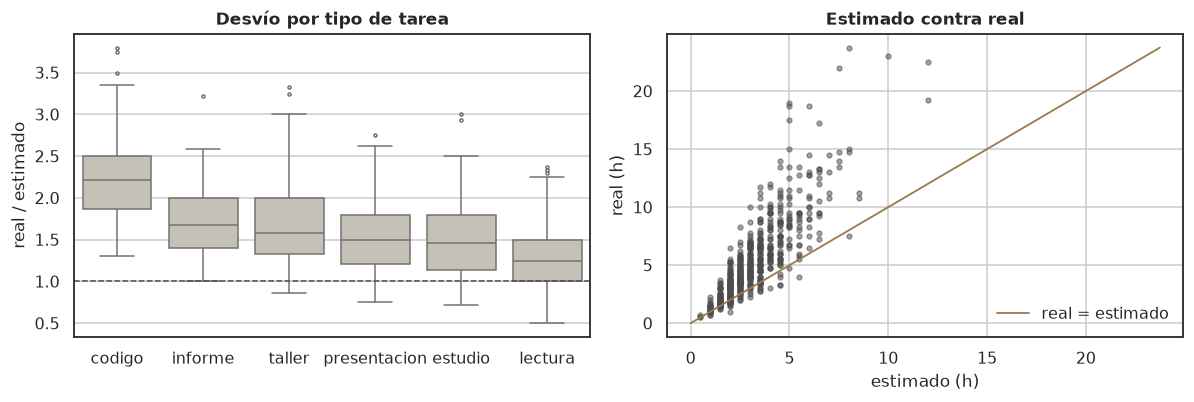

In [5]:
datos["razon"] = datos["real_h"] / datos["estimado_h"]
resumen = datos.groupby("tipo_tarea")["razon"].agg(["median", "mean", "count"]).sort_values("median", ascending=False)
display(resumen)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=datos, x="tipo_tarea", y="razon", order=resumen.index, color="#c9c2b4", ax=ejes[0], fliersize=2)
ejes[0].axhline(1, color=GRIS, linestyle="--", linewidth=1)
ejes[0].set(title="Desvío por tipo de tarea", xlabel="", ylabel="real / estimado")
ejes[1].scatter(datos["estimado_h"], datos["real_h"], s=10, color=GRIS, alpha=0.5)
tope = datos[["estimado_h", "real_h"]].max().max()
ejes[1].plot([0, tope], [0, tope], color=OCRE, linewidth=1.2, label="real = estimado")
ejes[1].set(title="Estimado contra real", xlabel="estimado (h)", ylabel="real (h)")
ejes[1].legend(frameon=False)
plt.tight_layout()

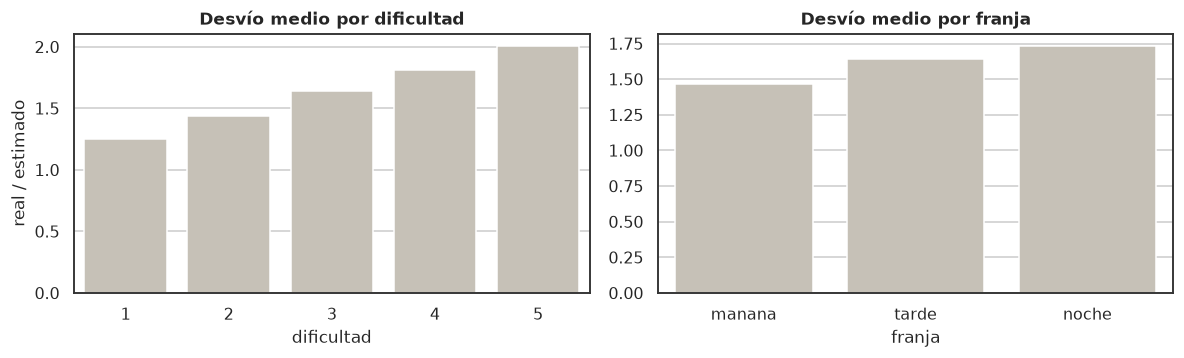

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.barplot(data=datos, x="dificultad", y="razon", color="#c9c2b4", errorbar=None, ax=ejes[0])
ejes[0].set(title="Desvío medio por dificultad", ylabel="real / estimado")
sns.barplot(data=datos, x="franja", y="razon", order=["manana", "tarde", "noche"], color="#c9c2b4", errorbar=None, ax=ejes[1])
ejes[1].set(title="Desvío medio por franja", ylabel="")
plt.tight_layout()

## Cómo entra la encuesta

Cuando haya respuestas, se exportan de Google Sheets a `data/encuesta_tiempos.csv` con las mismas columnas (`materia, tipo_tarea, dificultad, estimado_h, real_h, dia_semana, franja`). `ml.entrenar.cargar_tiempos()` las une a los datos sintéticos y al historial de uso, marcando cada fila con su fuente. Las preguntas del formulario están en `docs/encuesta.md`.

Con la encuesta se podrán responder con datos reales las dos preguntas del proyecto: en qué porcentaje subestiman los estudiantes sus tareas y si varía por tipo de tarea.

In [7]:
from ml.entrenar import RUTA_ENCUESTA, cargar_tiempos

todos = cargar_tiempos()
print("Encuesta disponible:", RUTA_ENCUESTA.exists())
todos["fuente"].value_counts()

Encuesta disponible: False


fuente
sintetico    600
Name: count, dtype: int64